# ExoHabitAI Data Preprocessing

This notebook performs reproducible, read-only inspection of the NASA Exoplanet Archive export. It preserves the raw dataframe in memory and does not create a cleaned dataset, synthetic target, or model artifact.

## 1. Imports and Configuration

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option('display.max_columns', 120)
pd.set_option('display.max_rows', 120)
sns.set_theme(style='whitegrid')

# Support execution from either the project root or the notebooks directory.
current_directory = Path.cwd().resolve()
PROJECT_ROOT = current_directory.parent if current_directory.name == 'notebooks' else current_directory
RAW_CSV_PATH = PROJECT_ROOT / 'data' / 'raw' / 'PS_2026.10.23_03.31.22.csv'

if not RAW_CSV_PATH.is_file():
    raise FileNotFoundError(f'Raw CSV not found: {RAW_CSV_PATH}')

print(f'Project root: {PROJECT_ROOT}')
print(f'Raw CSV: {RAW_CSV_PATH}')

Project root: C:\Users\shish\Desktop\Exohabit-Mini-Project-
Raw CSV: C:\Users\shish\Desktop\Exohabit-Mini-Project-\data\raw\PS_2026.10.23_03.31.22.csv


## 2. Raw Dataset Loading

NASA Archive exports include comment metadata before the CSV header. The first non-empty, non-comment line is detected as the header so the loader does not depend on a fixed metadata-line count.

In [2]:
def find_csv_header_line(path: Path) -> tuple[int, list[str]]:
    metadata_lines = []
    with path.open('r', encoding='utf-8', newline='') as file:
        for line_number, line in enumerate(file):
            stripped_line = line.strip()
            if not stripped_line or stripped_line.startswith('#'):
                if stripped_line.startswith('#'):
                    metadata_lines.append(stripped_line)
                continue
            return line_number, metadata_lines
    raise ValueError('Could not find a CSV header line.')

header_line_index, metadata_lines = find_csv_header_line(RAW_CSV_PATH)
raw_header_line = RAW_CSV_PATH.read_text(encoding='utf-8').splitlines()[header_line_index]
raw_df = pd.read_csv(RAW_CSV_PATH, skiprows=header_line_index)

# Keep a deep copy as the in-memory working snapshot. No transformations are applied.
df = raw_df.copy(deep=True)

print(f'Metadata comment lines before header: {len(metadata_lines)}')
print(f'Header line (1-based): {header_line_index + 1}')
print(f'Loaded shape: {raw_df.shape}')
print(f'Raw snapshot equals working dataframe: {raw_df.equals(df)}')

Metadata comment lines before header: 96
Header line (1-based): 97
Loaded shape: (40350, 92)
Raw snapshot equals working dataframe: True


## 3. Dataset Shape and Schema

In [3]:
print(f'Rows: {df.shape[0]:,}')
print(f'Columns: {df.shape[1]:,}')

schema = pd.DataFrame({
    'column': df.columns,
    'dtype': df.dtypes.astype(str).values,
    'non_null': df.notna().sum().values,
    'unique_values': df.nunique(dropna=True).values,
})
display(schema)

Rows: 40,350
Columns: 92


,column,dtype,non_null,unique_values
0,pl_name,str,40350,6451
1,hostname,str,40350,4847
2,default_flag,int64,40350,2
3,sy_snum,int64,40350,4
4,sy_pnum,int64,40350,8
5,discoverymethod,str,40350,11
6,disc_year,int64,40350,34
7,disc_facility,str,40350,73
8,soltype,str,40350,9
9,pl_controv_flag,int64,40350,2


## 4. Missing-Value Analysis

Counts and percentages are calculated from the loaded dataframe. No imputation or row removal is performed.

In [4]:
missing_analysis = pd.DataFrame({
    'missing_count': df.isna().sum(),
    'missing_percent': (df.isna().mean() * 100).round(3),
}).sort_values(['missing_count', 'missing_percent'], ascending=False)
display(missing_analysis)

,missing_count,missing_percent
pl_eqterr1,37558,93.081
pl_eqterr2,37558,93.081
st_spectype,37150,92.069
pl_orbeccenerr2,36320,90.012
pl_orbeccenerr1,36319,90.010
pl_bmassjerr1,33404,82.786
pl_bmassjerr2,33404,82.786
pl_bmasseerr1,33398,82.771
pl_bmasseerr2,33398,82.771
pl_bmassj,32695,81.029


## 5. Duplicate Analysis

Exact duplicate rows are reported separately from repeated planet and host names. Repeated names are not treated as duplicate records because the NASA export contains multiple parameter solutions.

In [5]:
exact_duplicate_rows = int(df.duplicated(keep=False).sum())
duplicate_rows_after_first = int(df.duplicated().sum())
planet_name_counts = df['pl_name'].value_counts(dropna=False)
host_name_counts = df['hostname'].value_counts(dropna=False)

duplicate_summary = pd.Series({
    'exact_duplicate_rows': exact_duplicate_rows,
    'duplicate_rows_after_first': duplicate_rows_after_first,
    'distinct_repeated_planet_names': int((planet_name_counts > 1).sum()),
    'distinct_repeated_host_names': int((host_name_counts > 1).sum()),
})
display(duplicate_summary.to_frame('value'))

print('Most frequent repeated planet names:')
display(planet_name_counts[planet_name_counts > 1].head(20).to_frame('row_count'))
print('Most frequent repeated host names:')
display(host_name_counts[host_name_counts > 1].head(20).to_frame('row_count'))

,value
exact_duplicate_rows,80
duplicate_rows_after_first,57
distinct_repeated_planet_names,5514
distinct_repeated_host_names,4315


Most frequent repeated planet names:


,row_count
pl_name,
TrES-2 b,34
Kepler-10 b,25
GJ 436 b,24
HAT-P-7 b,24
HAT-P-11 b,23
HD 209458 b,23
WASP-4 b,22
55 Cnc e,21
HD 189733 b,21


Most frequent repeated host names:


,row_count
hostname,
Kepler-11,103
Kepler-80,95
Kepler-32,91
KOI-351,81
Kepler-186,80
Kepler-20,76
Kepler-102,73
Kepler-79,70
Kepler-296,69


## 6. Summary Statistics

The numeric summary is descriptive only. It does not select features, impute values, or define a target.

In [6]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = df.select_dtypes(exclude=np.number).columns.tolist()

print(f'Numeric columns: {len(numeric_columns)}')
print(f'Categorical/text columns: {len(categorical_columns)}')
display(df[numeric_columns].describe().T)

Numeric columns: 76
Categorical/text columns: 16


,count,mean,std,min,25%,50%,75%,max
default_flag,40350.0,0.159876,3.664956e-01,0.000000e+00,0.000000,0.000000,0.000000,1.000000e+00
sy_snum,40350.0,1.086221,3.121313e-01,1.000000e+00,1.000000,1.000000,1.000000,4.000000e+00
sy_pnum,40350.0,1.916357,1.239821e+00,1.000000e+00,1.000000,1.000000,2.000000,8.000000e+00
disc_year,40350.0,2015.715886,4.219712e+00,1.992000e+03,2014.000000,2016.000000,2016.000000,2.026000e+03
pl_controv_flag,40350.0,0.004139,6.420092e-02,0.000000e+00,0.000000,0.000000,0.000000,1.000000e+00
pl_orbper,36955.0,11848.430248,2.092385e+06,9.070629e-02,4.348960,10.290994,26.444400,4.020000e+08
pl_orbpererr1,35216.0,13699.927386,2.504720e+06,0.000000e+00,0.000008,0.000038,0.000201,4.700000e+08
pl_orbpererr2,35215.0,-3229.577413,5.341167e+05,-1.000000e+08,-0.000200,-0.000038,-0.000008,0.000000e+00
pl_orbperlim,36955.0,-0.000244,2.014574e-02,-1.000000e+00,0.000000,0.000000,0.000000,1.000000e+00
pl_orbsmax,22455.0,4.726699,1.790478e+02,4.400000e-03,0.054500,0.101500,0.223900,1.900000e+04


## 7. Missing-Value Heatmap

For readability, the visualization uses at most the first 1,000 rows. The dataframe itself remains unchanged.

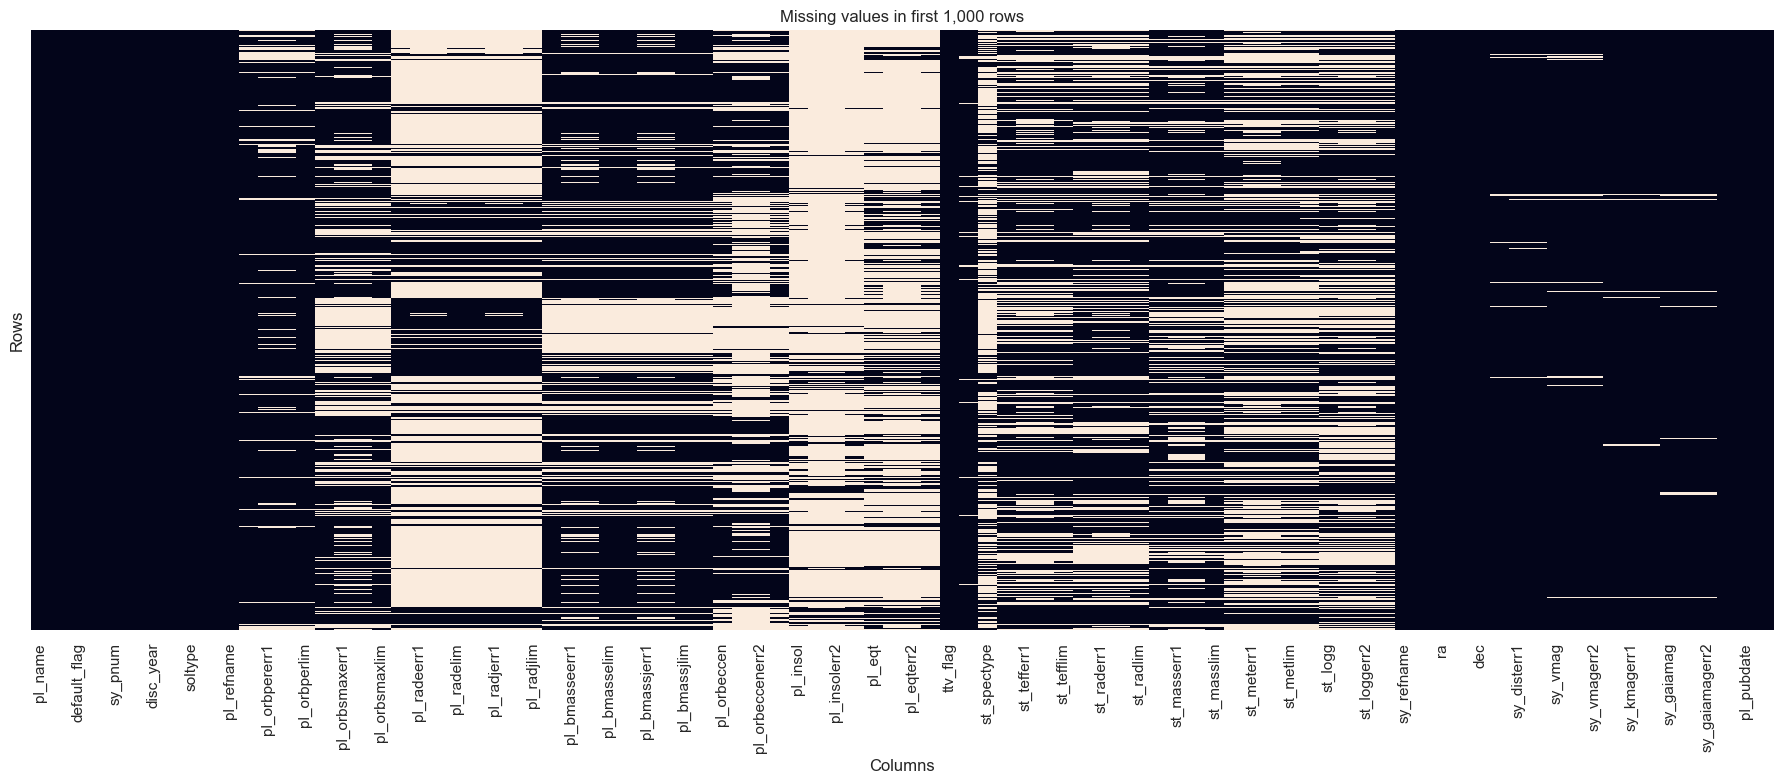

In [7]:
heatmap_rows = min(len(df), 1000)
plt.figure(figsize=(18, 8))
sns.heatmap(df.isna().iloc[:heatmap_rows], cbar=False, yticklabels=False)
plt.title(f'Missing values in first {heatmap_rows:,} rows')
plt.xlabel('Columns')
plt.ylabel('Rows')
plt.tight_layout()
plt.show()

## 8. Unit and Data-Quality Checks

The NASA metadata comments are retained for unit review. Checks below flag suspicious values and representation differences without correcting them.

In [8]:
unit_metadata = [line for line in metadata_lines if line.startswith('# COLUMN')]
print('NASA column documentation:')
print('\n'.join(unit_metadata))

measurement_columns = [
    'pl_orbper', 'pl_orbsmax', 'pl_rade', 'pl_radj', 'pl_bmasse',
    'pl_bmassj', 'pl_orbeccen', 'pl_insol', 'pl_eqt', 'st_teff',
    'st_rad', 'st_mass', 'sy_dist',
]
negative_measurements = {
    column: int((df[column] < 0).sum())
    for column in measurement_columns
    if column in df.columns and (df[column] < 0).any()
}
print('Negative values in selected non-error measurements:')
print(negative_measurements or 'None found')

binary_flag_columns = ['default_flag', 'pl_controv_flag', 'ttv_flag']
for column in binary_flag_columns:
    print(f'{column} values: {sorted(df[column].dropna().unique().tolist())}')

categorical_checks = ['soltype', 'pl_bmassprov', 'st_metratio']
for column in categorical_checks:
    print(f'\n{column} values:')
    display(df[column].value_counts(dropna=False).head(20).to_frame('row_count'))

date_pattern_checks = {}
for column in ['rowupdate', 'pl_pubdate', 'releasedate']:
    values = df[column].dropna().astype(str)
    nonstandard = values[~values.str.match(r'^\d{4}(-\d{2}){1,2}$')]
    date_pattern_checks[column] = {
        'distinct_values': int(values.nunique()),
        'nonstandard_examples': nonstandard.unique()[:10].tolist(),
    }
display(pd.DataFrame(date_pattern_checks).T)

print('No target variable is created in this notebook.')

NASA column documentation:
# COLUMN pl_name:        Planet Name
# COLUMN hostname:       Host Name
# COLUMN default_flag:   Default Parameter Set
# COLUMN sy_snum:        Number of Stars
# COLUMN sy_pnum:        Number of Planets
# COLUMN discoverymethod: Discovery Method
# COLUMN disc_year:      Discovery Year
# COLUMN disc_facility:  Discovery Facility
# COLUMN soltype:        Solution Type
# COLUMN pl_controv_flag: Controversial Flag
# COLUMN pl_refname:     Planetary Parameter Reference
# COLUMN pl_orbper:      Orbital Period [days]
# COLUMN pl_orbpererr1:  Orbital Period Upper Unc. [days]
# COLUMN pl_orbpererr2:  Orbital Period Lower Unc. [days]
# COLUMN pl_orbperlim:   Orbital Period Limit Flag
# COLUMN pl_orbsmax:     Orbit Semi-Major Axis [au]
# COLUMN pl_orbsmaxerr1: Orbit Semi-Major Axis Upper Unc. [au]
# COLUMN pl_orbsmaxerr2: Orbit Semi-Major Axis Lower Unc. [au]
# COLUMN pl_orbsmaxlim:  Orbit Semi-Major Axis Limit Flag
# COLUMN pl_rade:        Planet Radius [Earth Radius]


,row_count
soltype,
Published Confirmed,20729
Kepler Project Candidate (q1_q17_dr25_sup_koi),2736
Kepler Project Candidate (q1_q16_koi),2723
Kepler Project Candidate (q1_q17_dr25_koi),2719
Kepler Project Candidate (q1_q17_dr24_koi),2702
Kepler Project Candidate (q1_q12_koi),2681
Kepler Project Candidate (q1_q8_koi),2308
Published Candidate,2197
TESS Project Candidate,1555



pl_bmassprov values:


,row_count
pl_bmassprov,
NaN,32694
Mass,5194
Msini,2434
Msin(i)/sin(i),28



st_metratio values:


,row_count
st_metratio,
[Fe/H],20949
NaN,15375
[M/H],4006
[m/H],20


,distinct_values,nonstandard_examples
rowupdate,543,[]
pl_pubdate,313,[2017-08-31 00:00]
releasedate,514,"[2019-12-02 09:30:00, 2019-11-01 14:48:28, 202..."


No target variable is created in this notebook.


## Next Step

After the preprocessing instructions and exact feature contract are confirmed, define the parameter-solution selection policy, normalize documented units and categorical representations, decide a missingness strategy, and design target provenance. Keep the original CSV unchanged.